In [2]:
from torchvision.datasets import HMDB51, UCF101
from pytorchvideo.data.hmdb51 import Hmdb51
from pytorchvideo.data.ucf101 import Ucf101
from pytorchvideo.data.clip_sampling import UniformClipSampler
import os
import pickle


dataset_train = UCF101(
    root="datasets/ucf101/data/UCF-101",
    annotation_path="datasets/ucf101/test_train_splits/ucfTrainTestlist",
    frames_per_clip=64,
    step_between_clips=64,
    num_workers=4,
    train=False,
    output_format="TCHW",
)

100%|██████████| 833/833 [01:33<00:00,  8.89it/s]
d:\Programy\Anaconda\envs\msc\lib\site-packages\torchvision\datasets\video_utils.py:219: UserWarning: There aren't enough frames in the current video to get a clip for the given clip length and frames between clips. The video (and potentially others) will be skipped.
  warnings.warn(


In [5]:
s = set()

for i, k in enumerate(dataset_train):
    s.add(k[2])
    print(f"{i+1}/{len(dataset_train)}")

d:\Programy\Anaconda\envs\msc\lib\site-packages\torchvision\io\video.py:169: UserWarning: The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.
  warnings.warn("The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.")


1/8911
2/8911
3/8911
4/8911
5/8911
6/8911
7/8911
8/8911
9/8911
10/8911
11/8911
12/8911
13/8911
14/8911
15/8911
16/8911
17/8911
18/8911
19/8911
20/8911
21/8911
22/8911
23/8911
24/8911
25/8911
26/8911
27/8911
28/8911
29/8911
30/8911
31/8911
32/8911
33/8911
34/8911
35/8911
36/8911
37/8911
38/8911
39/8911
40/8911
41/8911
42/8911
43/8911
44/8911
45/8911
46/8911
47/8911
48/8911
49/8911
50/8911
51/8911
52/8911
53/8911
54/8911
55/8911
56/8911
57/8911
58/8911
59/8911
60/8911
61/8911
62/8911
63/8911
64/8911
65/8911
66/8911
67/8911
68/8911
69/8911
70/8911
71/8911
72/8911
73/8911
74/8911
75/8911
76/8911
77/8911
78/8911
79/8911
80/8911
81/8911
82/8911
83/8911
84/8911
85/8911
86/8911
87/8911
88/8911
89/8911
90/8911
91/8911
92/8911
93/8911
94/8911
95/8911
96/8911
97/8911
98/8911
99/8911
100/8911
101/8911
102/8911
103/8911
104/8911
105/8911
106/8911
107/8911
108/8911
109/8911
110/8911
111/8911
112/8911
113/8911
114/8911
115/8911
116/8911
117/8911
118/8911
119/8911
120/8911
121/8911
122/8911
123/8911
1

In [7]:
len(sorted(list(s)))

101

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from utils import show_img_chw

In [5]:
import wandb
from datasets import get_dataset
import torch
from utils import save_run, load_run
from funcs import train_epoch, val_epoch, test_epoch
from weight_inits import init_timesformer
from torch.utils.data import DataLoader
from models.vivit_custom.utils.scheduler import WarmupCosineSchedule
from transforms import get_transforms, Div255, SplitEqually

from constants import get_classes
from transformers import TimesformerConfig, TimesformerForVideoClassification
from transformers import ViTForImageClassification
from pytorchvideo.transforms import MixUp
import torch
from torchvision.transforms.v2 import (
    ScaleJitter,
    RandAugment,
    RandomCrop,
    Compose,
    ColorJitter,
    RandomHorizontalFlip,
    Normalize,
    RandomApply,
    UniformTemporalSubsample,
    CenterCrop,
    Lambda,
)
from pytorchvideo.transforms import UniformTemporalSubsample, ApplyTransformToKey

In [6]:
frames=8
CLASSES_LIST = get_classes('ucf101')

In [23]:
ds_transform_train = Compose(
   transforms=[
       UniformTemporalSubsample(num_samples=frames, temporal_dim=0),
       RandomHorizontalFlip(p=0.5),
       ScaleJitter(target_size=(240, 320), scale_range=(0.9, 1.33)),
       RandomCrop(size=(224, 224), pad_if_needed=True, fill=128),
       RandomApply(p=0.8, transforms=[ColorJitter(brightness=0.1, contrast=0.1, saturation=0.0, hue=0.0)]),
       RandAugment(num_ops=2, magnitude=10, fill=128),
       Div255(),
       Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
   ]
)

ds_transform_valid = Compose(
   transforms=[
       UniformTemporalSubsample(num_samples=frames, temporal_dim=0),
       CenterCrop((224, 224)),
       Div255(),
       Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
   ]
)

test_transform = Compose(
   [
       ApplyTransformToKey(
           key="video",
           transform=Compose(
               [
                   Lambda(lambda x: x.type(torch.uint8)),
                   Lambda(lambda x: x.permute(1, 0, 2, 3)),
                   SplitEqually(num_frames=64),
                   UniformTemporalSubsample(num_samples=8, temporal_dim=-4),
                   CenterCrop(size=(224, 224)),
                   Div255(),
                   Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
               ]
           ),
       ),
       ApplyTransformToKey(key="label", transform=Compose([lambda x: CLASSES_LIST.index(x)])),
   ]
)

In [24]:
dataset_train, dataset_valid, dataset_test = get_dataset(
     "ucf101",
     ds_transform_train,
     ds_transform_valid,
     test_transform,
     lazy=False
)

100%|██████████| 833/833 [01:28<00:00,  9.42it/s]
d:\Programy\Anaconda\envs\msc\lib\site-packages\torchvision\datasets\video_utils.py:219: UserWarning: There aren't enough frames in the current video to get a clip for the given clip length and frames between clips. The video (and potentially others) will be skipped.
  warnings.warn(
100%|██████████| 833/833 [01:30<00:00,  9.20it/s]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Biking


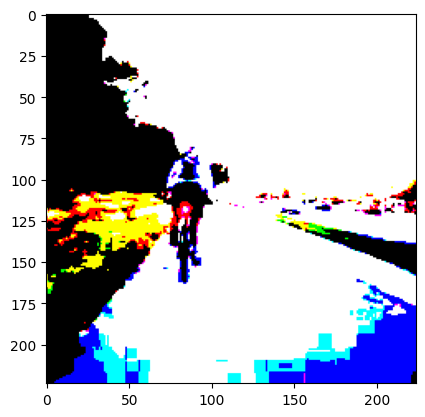

In [ ]:
n = 2000
print(CLASSES_LIST[dataset_train[n][2]])
show_img_chw(dataset_train[n][0][0])